# Figure S31: ACVRL1 fine-mapping and PromoterAI predictions

ACVRL1 locus fine-mapping and PromoterAI substitution predictions.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_PAPER_ROOT` to the local
paper directory and `QTL_SOURCE_ROOT` to the figure checkout with staged inputs
and saved objects. For example, set these variables in the R session before
you run the cells. Paths can contain spaces.

Run the cells from top to bottom. The preparation links show the filters, joins,
and counts used to produce the plot inputs. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Prepare the plotted data

The scripts below prepare filters, joins, counts, and summaries from source result tables. Their inputs and execution order are listed in `preparation/manifest.json`. The source data are not included in Git.

- [fig5-s31](../../preparation/Fig5/prepare_s31.R): Prepare ACVRL1 source rows and prediction windows; rebuild E and update every D QTL plotting frame in the accepted locus renderer; save the D/E objects consumed by S31.

Run `python3 tools/prepare_figure_data.py --list` from the repository root. Use the named root options described in `preparation/README.md`. Set `QTL_PREP_ROOT` to that run's output directory before running this notebook. The notebook then reads generated files from its `paper/` and `source/` folders. Other inputs and reference images still come from the original roots. A script with an unavailable source input is identified in the preparation manifest.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
prepared_root <- Sys.getenv("QTL_PREP_ROOT")
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  path <- file.path(root, relative)
  if (nzchar(prepared_root) && variable %in% c("QTL_PAPER_ROOT", "QTL_SOURCE_ROOT")) {
    namespace <- if (variable == "QTL_PAPER_ROOT") "paper" else "source"
    prepared_relative <- file.path(namespace, relative)
    generated <- file.path(prepared_root, prepared_relative)
    if (file.exists(generated)) {
      path <- generated
      variable <- "QTL_PREP_ROOT"
      relative <- prepared_relative
    }
  }
  if (!file.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  input_records[[paste(variable, relative, sep = ":")]] <- list(
    root = variable, path = relative, md5 = unname(tools::md5sum(path)))
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Read the saved ACVRL1 panels

Restore S31 from the saved Figure 5 ACVRL1 locus and PromoterAI objects. No fine-mapping, motif scan, or sequence model is run. The saved objects include the annotations and prediction coordinates needed to draw the panels.


In [2]:
locus <- readRDS(source_file("Fig5/objects/D.rds"))
predictions <- readRDS(source_file("Fig5/objects/E.rds"))
stopifnot(inherits(locus, "patchwork"), inherits(predictions, "ggplot"),
          all(c("promoterAI", "relative_position", "facet_id") %in% names(predictions$data)))


## Restore fine-mapping and prediction panels

Panel A shows saved hg38 locus PIPs, credible sets, rare-variant markers, the promoter inset, ENCODE elements, and gene models. Panel B shows saved PromoterAI single-nucleotide predictions in three 20-bp windows. The signed-square prediction axis and focal-variant labels remain unchanged. The SP1 band is a saved manual annotation.


(`geom_point()`).

(`geom_point()`).

Please use `theme()` to construct themes.

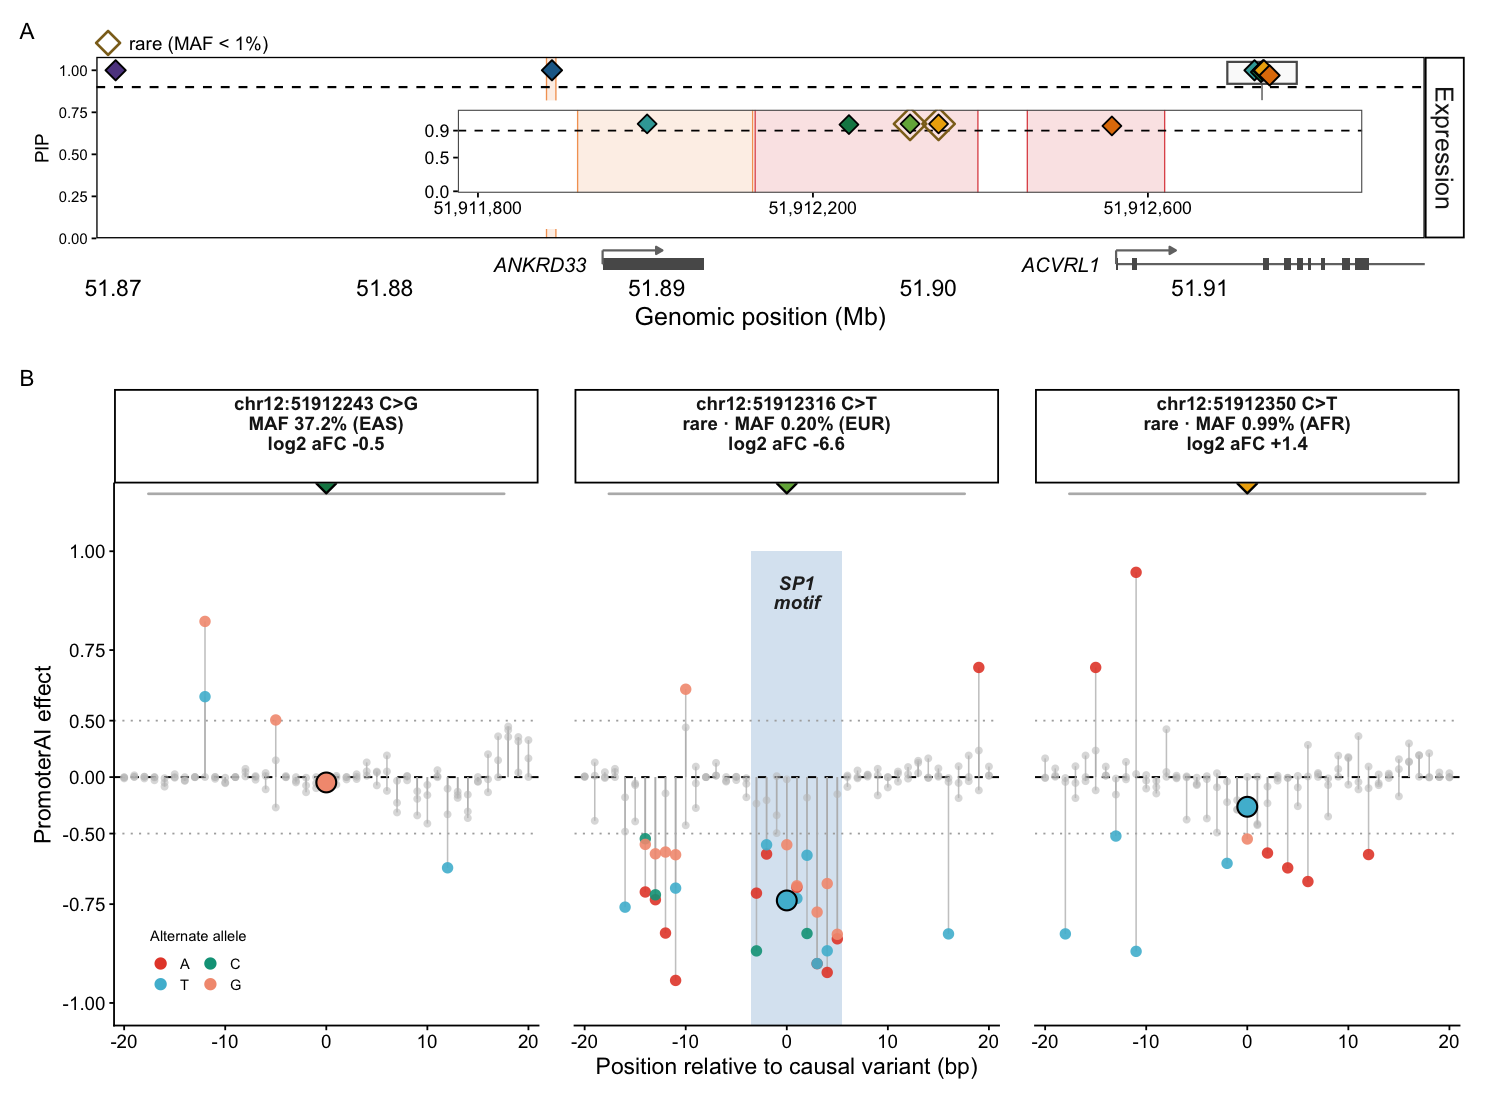

In [3]:
remove_headings <- function(plot) {
  if (inherits(plot, "patchwork")) {
    plot$patches$annotation$title <- NULL
    plot$patches$annotation$subtitle <- NULL
    plot$patches$annotation$theme <- theme()
    plot$patches$plots <- lapply(plot$patches$plots, remove_headings)
  }
  plot + labs(title = NULL, subtitle = NULL) +
    theme(plot.title = element_blank(), plot.subtitle = element_blank())
}
locus <- remove_headings(locus)
# Use ASCII log2 in strip text. Some device fonts do not contain subscript 2.
# This changes the display labels only; all prediction values are retained.
original_labeller <- predictions$facet$params$labeller
predictions$facet$params$labeller <- function(labels, multi_line = TRUE) {
  labels <- lapply(labels, function(x) stringr::str_replace_all(as.character(x), fixed("\u2082"), "2"))
  original_labeller(labels, multi_line = multi_line)
}
class(predictions$facet$params$labeller) <- c("function", "labeller")
locus_panel <- patchwork::wrap_elements(full = patchwork::patchworkGrob(locus))
figure <- locus_panel / predictions + patchwork::plot_layout(heights = c(76, 138)) +
  patchwork::plot_annotation(tag_levels = "A") &
  theme(plot.title = element_blank(), plot.subtitle = element_blank())
print(figure)


## Save aggregate outputs

Export the two-panel figure and counts per prediction window. Predictions describe model output, not an experimental test of regulatory activity or pathogenicity. No variant or participant source table is exported.


In [4]:
save_plot(figure, "supplements/S31", 184, 220)
readr::write_tsv(predictions$data %>% group_by(facet_id) %>%
                   summarise(substitution_predictions = n(), positions = n_distinct(relative_position),
                             minimum_prediction = min(promoterAI), maximum_prediction = max(promoterAI), .groups = "drop"),
                 output_file("supplements/S31_prediction_summary.tsv"))


Export aggregate plot: supplements/S31


Please use `theme()` to construct themes.

Please use `theme()` to construct themes.